<a href="https://colab.research.google.com/github/gitsyanteliz/herramientasbasicas-anteliz-gitsy/blob/main/TP_Final_Spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Integrador Final
### Análisis de canciones de Spotify 🎵
**Autora:** GITSY ANTELIZ · **Curso:** Herramientas básicas para el Análisis de Datos (UTN.BA)

## 1. Objetivos del análisis
**Dataset:** Spotify Tracks Dataset (Kaggle, autor MaharshiPandya). Canciones de Spotify con su género, popularidad y características de audio.

**Preguntas de investigación:**
1. ¿Qué géneros tienen mayor popularidad?
2. ¿Las canciones más bailables son más populares?
3. ¿Las canciones con letra explícita son más o menos populares?

**Hipótesis:** las canciones con letra explícita son más populares.

## 2. Carga de datos

Se tomó una muestra aleatoria de 10.000 canciones de las 114.000 del dataset completo (random_state=42, para que el resultado sea reproducible). Se eligió 10.000 porque cumple a la vez con la guía del TP (500 a 10.000 registros) y con la consigna (10.000 a 2 millones), y porque da unas 88 canciones por género, lo que hace más confiables los promedios por género.

**Para reproducir el análisis:** el archivo `dataset.csv` no está en este repositorio. Descárgalo desde [Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset), súbelo a tu Google Drive y cambia la variable `ruta` de la celda de abajo por la ubicación de tu archivo.

In [1]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

ruta = "/content/drive/MyDrive/Colab Notebooks/dataset.csv"
df_completo = pd.read_csv(ruta)

print("Filas y columnas:", df_completo.shape)
df_completo.head()

Mounted at /content/drive
Filas y columnas: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [2]:
df = df_completo.sample(10000, random_state=42)
print("Filas y columnas de la muestra:", df.shape)
df.head()

Filas y columnas de la muestra: (10000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
113186,113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,...,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
42819,42819,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,...,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
59311,59311,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,...,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
91368,91368,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,...,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
61000,61000,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,...,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


In [3]:
(10000, 21)

(10000, 21)

## 3. Diagnóstico de los datos

In [4]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
113186,113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,...,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
42819,42819,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,...,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
59311,59311,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,...,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
91368,91368,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,...,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
61000,61000,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,...,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


In [5]:
df.shape

(10000, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 113186 to 104671
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        10000 non-null  int64  
 1   track_id          10000 non-null  object 
 2   artists           9999 non-null   object 
 3   album_name        9999 non-null   object 
 4   track_name        9999 non-null   object 
 5   popularity        10000 non-null  int64  
 6   duration_ms       10000 non-null  int64  
 7   explicit          10000 non-null  bool   
 8   danceability      10000 non-null  float64
 9   energy            10000 non-null  float64
 10  key               10000 non-null  int64  
 11  loudness          10000 non-null  float64
 12  mode              10000 non-null  int64  
 13  speechiness       10000 non-null  float64
 14  acousticness      10000 non-null  float64
 15  instrumentalness  10000 non-null  float64
 16  liveness          10000 non-null  float

In [7]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,56146.087900,32.912000,2.273241e+05,0.562903,0.643637,5.312600,-8.198694,0.634700,0.085345,0.317490,0.153797,0.216476,0.472950,122.534584,3.908800
std,32623.090848,22.259236,1.028147e+05,0.174618,0.253013,3.566252,4.930333,0.481538,0.108083,0.336439,0.306335,0.193939,0.260777,30.061590,0.421782
min,35.000000,0.000000,0.000000e+00,0.000000,0.000020,0.000000,-41.531000,0.000000,0.000000,0.000000,0.000000,0.013700,0.000000,0.000000,0.000000
25%,28314.000000,17.000000,1.739262e+05,0.451000,0.468000,2.000000,-10.003000,0.000000,0.036000,0.016375,0.000000,0.098200,0.253000,99.940500,4.000000
50%,55848.500000,34.000000,2.134390e+05,0.574000,0.687000,5.000000,-6.965500,1.000000,0.049100,0.169000,0.000044,0.133000,0.462500,122.249000,4.000000
75%,83896.750000,50.000000,2.607762e+05,0.691000,0.856000,8.000000,-4.977000,1.000000,0.085625,0.602000,0.050450,0.281000,0.682000,140.489250,4.000000
max,113986.000000,97.000000,4.334721e+06,0.975000,1.000000,11.000000,1.700000,1.000000,0.962000,0.996000,1.000000,0.992000,0.992000,243.372000,5.000000


In [8]:
df["track_genre"].value_counts()

,count
track_genre,
grindcore,120
grunge,105
industrial,104
samba,104
alt-rock,104
...,...
death-metal,73
psych-rock,73
trip-hop,73


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

,0
Unnamed: 0,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


In [11]:
df[df["artists"].isnull()]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [12]:
df[df["popularity"] == 0]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
59311,59311,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,...,-10.071,0,0.1440,0.613,0.001910,0.195,0.0887,75.564,3,iranian
91368,91368,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,...,-5.598,1,0.0279,0.406,0.000197,0.111,0.5980,109.991,3,rock
19261,19261,4ifiz8TRTNdG9ORNWh2P0Q,Kacey Musgraves;Lana Del Rey,Jingle Bell Rock 2022,I'll Be Home For Christmas - From The Kacey Mu...,0,132108,False,0.469,0.183,...,-15.414,1,0.0407,0.829,0.000000,0.710,0.3810,139.592,4,country
62735,62735,5xWxnLpw8ooMW1nJwY2hui,KIRINJI,J-Pop 輕旅行,時間がない,0,284160,False,0.772,0.675,...,-9.154,0,0.0366,0.124,0.012100,0.102,0.6800,126.033,4,j-pop
88581,88581,2pXg8l1JGZ3hCyFqxirV13,Lalo Ebratt;Trapical,Frescura y Perreo,Mocca,0,200293,False,0.786,0.696,...,-5.343,0,0.3520,0.183,0.000000,0.123,0.5910,97.956,4,reggae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89141,89141,0ZdyCcW6uUOBjb8CQvyg3m,KAROL G;Mariah Angeliq,Fiesta portatil,EL MAKINON,0,209160,False,0.689,0.705,...,-3.224,0,0.1020,0.256,0.000001,0.108,0.4560,89.109,4,reggaeton
11847,11847,0iFbxo4qoQXO5hVgTgGZ31,Rumer,Feeling Good - Adult Pop Favorites,Am I Forgiven?,0,210453,False,0.654,0.507,...,-9.359,1,0.0273,0.462,0.000002,0.109,0.6110,116.986,4,british
76140,76140,0bdhaLIxIWjrZpZdWRlPsq,Adolphe Adam;Luciano Pavarotti;National Philha...,Weihnachten Klassik 2022,O Holy Night,0,254693,False,0.150,0.300,...,-10.723,1,0.0407,0.973,0.006680,0.131,0.1170,55.329,4,opera
83048,83048,0k30CIxipiw4Vx0NLG6qqk,Swedish House Mafia;John Martin,Electro sounds,Don't You Worry Child - Radio Edit,0,211360,False,0.609,0.830,...,-3.229,0,0.0552,0.117,0.000000,0.180,0.4780,128.986,4,progressive-house


In [13]:
df[df["popularity"] == 0]["track_genre"].value_counts()

,count
track_genre,
jazz,71
iranian,63
country,60
romance,53
soul,50
...,...
idm,1
world-music,1
indian,1


### Hallazgos del diagnóstico
- Tamaño: la muestra tiene 10.000 filas y 21 columnas (tomada al azar de las 114.000 canciones del dataset completo).
- Vacíos: 1 canción sin artista, álbum ni nombre; además dura 0 segundos (valor imposible).
- Duplicados: hay 0 filas duplicadas.
- Tipos de datos: no hay contagio; las columnas numéricas son int64 o float64 y las 5 de texto (object) deben ser texto.
- Columna que no sirve: `Unnamed: 0` es solo el número de fila que guardó el creador del dataset. No describe la canción, así que la voy a quitar.
- Dato raro a investigar: hay 1.431 canciones con popularidad 0 (14,3 %). Están en muchos géneros, pero algunos tienen bastantes (jazz 71, iranian 63, country 60).

## 4. Limpieza de datos

In [14]:
data_set_limpio = df.copy()


In [15]:
data_set_limpio = data_set_limpio.drop(columns=["Unnamed: 0"])

In [16]:
data_set_limpio= data_set_limpio[data_set_limpio["duration_ms"] > 0]

In [17]:
data_set_limpio.shape

(9999, 20)

In [18]:
data_set_limpio["Dudoso"] =data_set_limpio["popularity"] == 0

In [19]:
data_set_limpio["Dudoso"].value_counts()

,count
Dudoso,
False,8569
True,1430


### Decisiones de limpieza
- Copia: realicé una copia de la tabla original (`data_set_limpio = df.copy()`) para no modificar los datos originales.
- Columna quitada: `Unnamed: 0` era solo el número de fila que guardó el creador del dataset. No aporta nada al análisis, así que la quité.
- Canción quitada: quité 1 canción porque dura 0 segundos (valor imposible: una canción sin duración no existe) y además no tiene artista, álbum ni nombre. Representa el 0,01 % de la muestra. Seguí el criterio de la guía del TP: excluir solo valores imposibles que sean una fracción mínima. Resultado: 9.999 canciones.
- Popularidad 0: había 1.430 canciones (14,3 %) con popularidad 0. Según la descripción del dataset en Kaggle, la popularidad depende de cuántas veces y qué tan recientemente se escucha una canción, así que un 0 no significa que nunca se haya escuchado. No las borré: las marqué en una columna Dudoso (1.430 True, 8.569 False) para comparar los resultados con y sin ellas.

## 5. Análisis

### Pregunta 1: ¿qué géneros tienen mayor popularidad?

In [20]:
data_set_limpio.groupby("track_genre")["popularity"].mean()

,popularity
track_genre,
acoustic,42.453608
afrobeat,22.802326
alt-rock,25.557692
alternative,22.186667
ambient,42.481928
...,...
techno,38.959184
trance,36.907895
trip-hop,34.945205


In [21]:
data_set_limpio.groupby("track_genre")["popularity"].mean().sort_values(ascending=False).head(10)

,popularity
track_genre,
pop-film,59.633663
k-pop,57.065217
chill,52.431579
sad,52.082192
grunge,49.819048
indian,49.323232
sertanejo,47.820225
anime,47.655172
hip-hop,46.989130


In [22]:
data_set_limpio.groupby("track_genre")["popularity"].agg(["mean", "count"]).sort_values("mean",ascending=False).head(10)

,mean,count
track_genre,,
pop-film,59.633663,101
k-pop,57.065217,92
chill,52.431579,95
sad,52.082192,73
grunge,49.819048,105
indian,49.323232,99
sertanejo,47.820225,89
anime,47.655172,87
hip-hop,46.989130,92


In [23]:
resumen_generos = data_set_limpio.groupby("track_genre")["popularity"].agg(["mean", "count"])

In [24]:
resumen_generos[resumen_generos["count"] >= 5].sort_values("mean", ascending=False).head(10)

,mean,count
track_genre,,
pop-film,59.633663,101
k-pop,57.065217,92
chill,52.431579,95
sad,52.082192,73
grunge,49.819048,105
indian,49.323232,99
sertanejo,47.820225,89
anime,47.655172,87
hip-hop,46.989130,92


### Conclusión pregunta 1
Con 10.000 canciones, el género más popular es pop-film (promedio 59,6), seguido de k-pop (57,1) y chill (52,4). Cada promedio se basa en entre 73 y 105 canciones, por lo que el resultado es mucho más confiable que con la muestra de 500, donde había solo 5 a 8 canciones por género.



In [25]:
top10 = resumen_generos[resumen_generos["count"] >= 5].sort_values("mean", ascending=False).head(10)

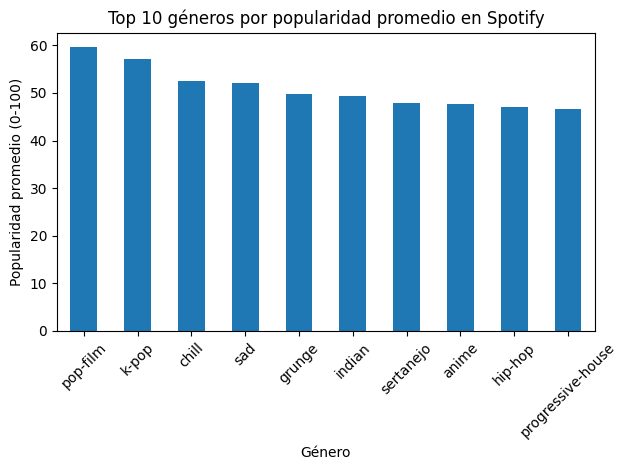

In [26]:
import matplotlib.pyplot as plt

top10["mean"].plot(kind="bar", rot=45)
plt.title("Top 10 géneros por popularidad promedio en Spotify")
plt.xlabel("Género")
plt.ylabel("Popularidad promedio (0-100)")
plt.tight_layout()
plt.show()

###Qué muestra el gráfico
La diferencia entre pop-film (59,6) y progressive-house (46,7), el último del top 10, es de unos 13 puntos en una escala de 0 a 100: una diferencia moderada. Limitación: la popularidad de Spotify mide cuánto se escucha una canción en el momento en que se tomaron los datos, y algunos géneros tienen muchas canciones con popularidad 0 (por ejemplo, jazz), lo que baja su promedio.


### Pregunta 2: ¿las canciones más bailables son más populares?

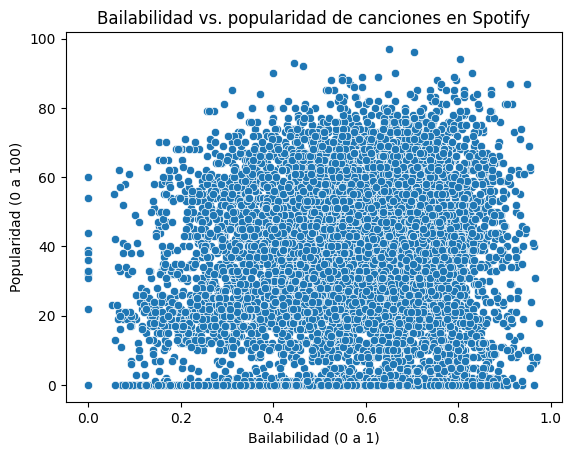

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=data_set_limpio, x="danceability", y="popularity")
plt.title("Bailabilidad vs. popularidad de canciones en Spotify")
plt.xlabel("Bailabilidad (0 a 1)")
plt.ylabel("Popularidad (0 a 100)")
plt.show()

In [28]:
sin_dudosos = data_set_limpio[data_set_limpio["Dudoso"] == False]

In [29]:
sin_dudosos.shape

(8569, 21)

In [30]:
data_set_limpio["danceability"].corr(data_set_limpio["popularity"])

np.float64(0.04822788315262216)

In [31]:
sin_dudosos["danceability"].corr(sin_dudosos["popularity"])

np.float64(0.07286413189958224)

### Conclusión pregunta 2
La correlación entre bailabilidad y popularidad es de 0,05 con todas las canciones y de 0,07 sin las canciones dudosas. En ambos casos es muy débil, casi nula (más débil todavía que con la muestra de 500, donde era de 0,10), y el gráfico de dispersión muestra una nube de puntos sin forma clara. Por lo tanto, no se puede afirmar que las canciones más bailables sean más populares: la bailabilidad prácticamente no se relaciona con la popularidad.

### Pregunta 3: ¿las canciones con letra explícita son más o menos populares?

In [32]:
data_set_limpio.groupby("explicit")["popularity"].agg(["mean", "count"])

,mean,count
explicit,,
False,32.640707,9168
True,35.944645,831


In [33]:
sin_dudosos.groupby("explicit")["popularity"].agg(["mean", "count"])

,mean,count
explicit,,
False,38.067676,7861
True,42.189266,708


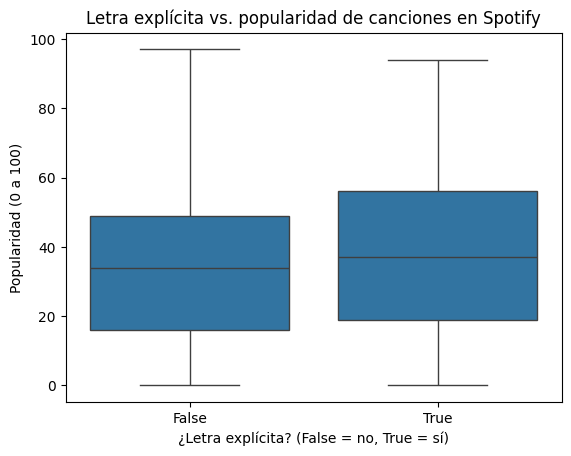

In [34]:
sns.boxplot(data=data_set_limpio, x="explicit", y="popularity")
plt.title("Letra explícita vs. popularidad de canciones en Spotify")
plt.xlabel("¿Letra explícita? (False = no, True = sí)")
plt.ylabel("Popularidad (0 a 100)")
plt.show()

### Conclusión pregunta 3
Las canciones explícitas tienen una popularidad promedio de 35,9, frente a 32,6 de las no explícitas: unos 3,3 puntos más. Sin las dudosas, la diferencia es de 4,1 puntos. El boxplot muestra que la caja de las explícitas está apenas más arriba. Con la muestra de 500 la diferencia parecía de 9 puntos, pero con más datos se redujo a 3,3: la muestra chica exageraba el resultado. Por lo tanto, la hipótesis se apoya, pero débilmente: las canciones explícitas son un poco más populares, aunque la diferencia es pequeña.

Limitaciones: las explícitas son una minoría (831 de 9.999, el 8 %), aunque son suficientes para un promedio confiable. Además, según la descripción del dataset en Kaggle, "False" incluye canciones no explícitas y también aquellas de las que no se sabe, así que algunas podrían estar mal clasificadas. Este resultado muestra una asociación, no prueba que la letra explícita cause mayor popularidad.

## 6. Síntesis

Se analizó una muestra aleatoria de 10.000 canciones de Spotify. 1) Géneros: pop-film es el más popular (promedio 59,6), seguido de k-pop (57,1). 2) Bailabilidad: su correlación con la popularidad es casi nula (0,05). 3) Explícitas: son un poco más populares (35,9 vs. 32,6), lo que apoya débilmente la hipótesis. Limitación: 1.430 canciones (14,3 %) tienen popularidad 0, y la popularidad refleja lo que se escucha en el momento de la recolección.

## KPIs principales

In [35]:
data_set_limpio.to_csv("/content/drive/MyDrive/Colab Notebooks/spotify_limpio.csv", index=False)

In [36]:
len(data_set_limpio)

9999

In [37]:
data_set_limpio["popularity"].mean()

np.float64(32.91529152915292)

In [38]:
data_set_limpio["track_genre"].nunique()

114

### KPIs principales
- Canciones analizadas: 9.999 (muestra limpia).
- Popularidad promedio: 32,9 sobre 100.
- Géneros distintos: 114 (Nota: la descripción de Kaggle dice 125, pero los datos tienen 114.)
Estos KPIs se mostrarán como tarjetas en el dashboard de Power BI.